In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib
import warnings
warnings.filterwarnings("ignore")

In [10]:
from google.colab import files

uploaded = files.upload()

Saving temperatures.csv to temperatures.csv


In [12]:
from google.colab import files

uploaded = files.upload()

Saving crop_yield.csv to crop_yield (1).csv


In [13]:
crop_df = pd.read_csv("crop_yield.csv")
temp_df = pd.read_csv("temperatures.csv")

print("Crop Dataset:")
print(crop_df.head())

print("\nTemperature Dataset:")
print(temp_df.head())

Crop Dataset:
           Crop  Crop_Year       Season  State     Area  Production  \
0      Arecanut       1997  Whole Year   Assam  73814.0       56708   
1     Arhar/Tur       1997  Kharif       Assam   6637.0        4685   
2   Castor seed       1997  Kharif       Assam    796.0          22   
3      Coconut        1997  Whole Year   Assam  19656.0   126905000   
4  Cotton(lint)       1997  Kharif       Assam   1739.0         794   

   Annual_Rainfall  Fertilizer  Pesticide        Yield  
0           2051.4  7024878.38   22882.34     0.796087  
1           2051.4   631643.29    2057.47     0.710435  
2           2051.4    75755.32     246.76     0.238333  
3           2051.4  1870661.52    6093.36  5238.051739  
4           2051.4   165500.63     539.09     0.420909  

Temperature Dataset:
   YEAR    JAN    FEB    MAR    APR    MAY    JUN    JUL    AUG    SEP    OCT  \
0  1901  22.40  24.14  29.07  31.91  33.41  33.18  31.21  30.39  30.47  29.97   
1  1902  24.93  26.58  29.77  31.

In [14]:
print("Crop dataset shape:", crop_df.shape)
print("Temperature dataset shape:", temp_df.shape)


Crop dataset shape: (19689, 10)
Temperature dataset shape: (117, 18)


In [15]:
print(crop_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19689 entries, 0 to 19688
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Crop             19689 non-null  object 
 1   Crop_Year        19689 non-null  int64  
 2   Season           19689 non-null  object 
 3   State            19689 non-null  object 
 4   Area             19689 non-null  float64
 5   Production       19689 non-null  int64  
 6   Annual_Rainfall  19689 non-null  float64
 7   Fertilizer       19689 non-null  float64
 8   Pesticide        19689 non-null  float64
 9   Yield            19689 non-null  float64
dtypes: float64(5), int64(2), object(3)
memory usage: 1.5+ MB
None


In [16]:
print(crop_df.describe())

          Crop_Year          Area    Production  Annual_Rainfall  \
count  19689.000000  1.968900e+04  1.968900e+04     19689.000000   
mean    2009.127584  1.799266e+05  1.643594e+07      1437.755177   
std        6.498099  7.328287e+05  2.630568e+08       816.909589   
min     1997.000000  5.000000e-01  0.000000e+00       301.300000   
25%     2004.000000  1.390000e+03  1.393000e+03       940.700000   
50%     2010.000000  9.317000e+03  1.380400e+04      1247.600000   
75%     2015.000000  7.511200e+04  1.227180e+05      1643.700000   
max     2020.000000  5.080810e+07  6.326000e+09      6552.700000   

         Fertilizer     Pesticide         Yield  
count  1.968900e+04  1.968900e+04  19689.000000  
mean   2.410331e+07  4.884835e+04     79.954009  
std    9.494600e+07  2.132874e+05    878.306193  
min    5.417000e+01  9.000000e-02      0.000000  
25%    1.880146e+05  3.567000e+02      0.600000  
50%    1.234957e+06  2.421900e+03      1.030000  
75%    1.000385e+07  2.004170e+04    

In [17]:
print(crop_df.isnull().sum())

Crop               0
Crop_Year          0
Season             0
State              0
Area               0
Production         0
Annual_Rainfall    0
Fertilizer         0
Pesticide          0
Yield              0
dtype: int64


In [18]:
print("Duplicate rows:", crop_df.duplicated().sum())

Duplicate rows: 0


In [19]:
print(temp_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 117 entries, 0 to 116
Data columns (total 18 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   YEAR     117 non-null    int64  
 1   JAN      117 non-null    float64
 2   FEB      117 non-null    float64
 3   MAR      117 non-null    float64
 4   APR      117 non-null    float64
 5   MAY      117 non-null    float64
 6   JUN      117 non-null    float64
 7   JUL      117 non-null    float64
 8   AUG      117 non-null    float64
 9   SEP      117 non-null    float64
 10  OCT      117 non-null    float64
 11  NOV      117 non-null    float64
 12  DEC      117 non-null    float64
 13  ANNUAL   117 non-null    float64
 14  JAN-FEB  117 non-null    float64
 15  MAR-MAY  117 non-null    float64
 16  JUN-SEP  117 non-null    float64
 17  OCT-DEC  117 non-null    float64
dtypes: float64(17), int64(1)
memory usage: 16.6 KB
None


In [20]:
print(temp_df.isnull().sum())

YEAR       0
JAN        0
FEB        0
MAR        0
APR        0
MAY        0
JUN        0
JUL        0
AUG        0
SEP        0
OCT        0
NOV        0
DEC        0
ANNUAL     0
JAN-FEB    0
MAR-MAY    0
JUN-SEP    0
OCT-DEC    0
dtype: int64


In [21]:
print("Temperature duplicate rows:", temp_df.duplicated().sum())

Temperature duplicate rows: 0


In [22]:
print("Crop years:")
print(crop_df["Crop_Year"].min(), "to", crop_df["Crop_Year"].max())

print("\nTemperature years:")
print(temp_df["YEAR"].min(), "to", temp_df["YEAR"].max())

Crop years:
1997 to 2020

Temperature years:
1901 to 2017


In [23]:
common_years = sorted(
    set(crop_df["Crop_Year"]).intersection(set(temp_df["YEAR"]))
)

print("Number of common years:", len(common_years))
print("Common years:", common_years)

Number of common years: 21
Common years: [1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017]


In [24]:
print("Crops:")
print(crop_df["Crop"].unique())


Crops:
['Arecanut' 'Arhar/Tur' 'Castor seed' 'Coconut ' 'Cotton(lint)'
 'Dry chillies' 'Gram' 'Jute' 'Linseed' 'Maize' 'Mesta' 'Niger seed'
 'Onion' 'Other  Rabi pulses' 'Potato' 'Rapeseed &Mustard' 'Rice'
 'Sesamum' 'Small millets' 'Sugarcane' 'Sweet potato' 'Tapioca' 'Tobacco'
 'Turmeric' 'Wheat' 'Bajra' 'Black pepper' 'Cardamom' 'Coriander' 'Garlic'
 'Ginger' 'Groundnut' 'Horse-gram' 'Jowar' 'Ragi' 'Cashewnut' 'Banana'
 'Soyabean' 'Barley' 'Khesari' 'Masoor' 'Moong(Green Gram)'
 'Other Kharif pulses' 'Safflower' 'Sannhamp' 'Sunflower' 'Urad'
 'Peas & beans (Pulses)' 'other oilseeds' 'Other Cereals' 'Cowpea(Lobia)'
 'Oilseeds total' 'Guar seed' 'Other Summer Pulses' 'Moth']


In [25]:
print("\nSeasons:")
print(crop_df["Season"].unique())


Seasons:
['Whole Year ' 'Kharif     ' 'Rabi       ' 'Autumn     ' 'Summer     '
 'Winter     ']


In [26]:
print("\nStates:")
print(crop_df["State"].unique())


States:
['Assam' 'Karnataka' 'Kerala' 'Meghalaya' 'West Bengal' 'Puducherry' 'Goa'
 'Andhra Pradesh' 'Tamil Nadu' 'Odisha' 'Bihar' 'Gujarat' 'Madhya Pradesh'
 'Maharashtra' 'Mizoram' 'Punjab' 'Uttar Pradesh' 'Haryana'
 'Himachal Pradesh' 'Tripura' 'Nagaland' 'Chhattisgarh' 'Uttarakhand'
 'Jharkhand' 'Delhi' 'Manipur' 'Jammu and Kashmir' 'Telangana'
 'Arunachal Pradesh' 'Sikkim']


In [27]:
crop_df = crop_df.drop_duplicates()

In [28]:
crop_df = crop_df.dropna(subset=["Yield"])

In [29]:
print("Shape after cleaning:", crop_df.shape)
print(crop_df.isnull().sum())

Shape after cleaning: (19689, 10)
Crop               0
Crop_Year          0
Season             0
State              0
Area               0
Production         0
Annual_Rainfall    0
Fertilizer         0
Pesticide          0
Yield              0
dtype: int64


In [30]:
temp_df = temp_df.drop_duplicates()
temp_df = temp_df.dropna(subset=["YEAR"])

In [31]:
print(temp_df.isnull().sum())

YEAR       0
JAN        0
FEB        0
MAR        0
APR        0
MAY        0
JUN        0
JUL        0
AUG        0
SEP        0
OCT        0
NOV        0
DEC        0
ANNUAL     0
JAN-FEB    0
MAR-MAY    0
JUN-SEP    0
OCT-DEC    0
dtype: int64


In [32]:
def get_season_temperature(row):
    season = str(row["Season"]).lower()

    if "kharif" in season:
        return row["JUN-SEP"]

    elif "rabi" in season:
        return (row["OCT-DEC"] + row["JAN-FEB"]) / 2

    elif "summer" in season:
        return row["MAR-MAY"]

    elif "winter" in season:
        return row["JAN-FEB"]

    elif "autumn" in season:
        return row["OCT-DEC"]

    else:
        return row["ANNUAL"]

In [33]:
merged_df = crop_df.merge(
    temp_df,
    left_on="Crop_Year",
    right_on="YEAR",
    how="inner"
)

print("Merged dataset shape:", merged_df.shape)

Merged dataset shape: (17510, 28)


In [34]:
merged_df.head()

,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield,...,AUG,SEP,OCT,NOV,DEC,ANNUAL,JAN-FEB,MAR-MAY,JUN-SEP,OCT-DEC
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087,...,31.04,31.11,29.21,26.87,23.92,29.05,24.63,31.26,31.77,26.65
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435,...,31.04,31.11,29.21,26.87,23.92,29.05,24.63,31.26,31.77,26.65
2,Castor seed,1997,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333,...,31.04,31.11,29.21,26.87,23.92,29.05,24.63,31.26,31.77,26.65
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739,...,31.04,31.11,29.21,26.87,23.92,29.05,24.63,31.26,31.77,26.65
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909,...,31.04,31.11,29.21,26.87,23.92,29.05,24.63,31.26,31.77,26.65


In [35]:
merged_df["Season_Temperature"] = merged_df.apply(
    get_season_temperature,
    axis=1
)

In [36]:
merged_df[
    ["Crop", "Crop_Year", "Season", "Season_Temperature", "Yield"]
].head(10)

,Crop,Crop_Year,Season,Season_Temperature,Yield
0,Arecanut,1997,Whole Year,29.05,0.796087
1,Arhar/Tur,1997,Kharif,31.77,0.710435
2,Castor seed,1997,Kharif,31.77,0.238333
3,Coconut,1997,Whole Year,29.05,5238.051739
4,Cotton(lint),1997,Kharif,31.77,0.420909
5,Dry chillies,1997,Whole Year,29.05,0.643636
6,Gram,1997,Rabi,25.64,0.465455
7,Jute,1997,Kharif,31.77,9.919565
8,Linseed,1997,Rabi,25.64,0.461364
9,Maize,1997,Kharif,31.77,0.615652


In [37]:
features = [
    "Crop",
    "Crop_Year",
    "Season",
    "State",
    "Area",
    "Annual_Rainfall",
    "Fertilizer",
    "Pesticide",
    "Season_Temperature"
]

target = "Yield"

In [38]:
X = merged_df[features]
y = merged_df[target]

In [39]:
print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
           Crop  Crop_Year       Season  State     Area  Annual_Rainfall  \
0      Arecanut       1997  Whole Year   Assam  73814.0           2051.4   
1     Arhar/Tur       1997  Kharif       Assam   6637.0           2051.4   
2   Castor seed       1997  Kharif       Assam    796.0           2051.4   
3      Coconut        1997  Whole Year   Assam  19656.0           2051.4   
4  Cotton(lint)       1997  Kharif       Assam   1739.0           2051.4   

   Fertilizer  Pesticide  Season_Temperature  
0  7024878.38   22882.34               29.05  
1   631643.29    2057.47               31.77  
2    75755.32     246.76               31.77  
3  1870661.52    6093.36               29.05  
4   165500.63     539.09               31.77  

Target:
0       0.796087
1       0.710435
2       0.238333
3    5238.051739
4       0.420909
Name: Yield, dtype: float64


In [40]:
print(X.isnull().sum())
print("\nTarget missing values:", y.isnull().sum())

Crop                  0
Crop_Year             0
Season                0
State                 0
Area                  0
Annual_Rainfall       0
Fertilizer            0
Pesticide             0
Season_Temperature    0
dtype: int64

Target missing values: 0


In [42]:
data = pd.concat([X, y], axis=1)
data = data.dropna()
X = data[features]
y = data[target]
print("Final dataset shape:", X.shape)

Final dataset shape: (17510, 9)


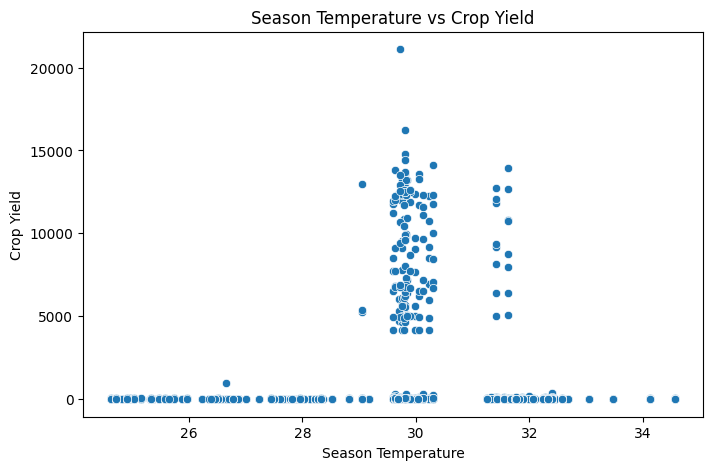

In [45]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=merged_df,
    x="Season_Temperature",
    y="Yield"
)

plt.title("Season Temperature vs Crop Yield")
plt.xlabel("Season Temperature")
plt.ylabel("Crop Yield")

plt.show()

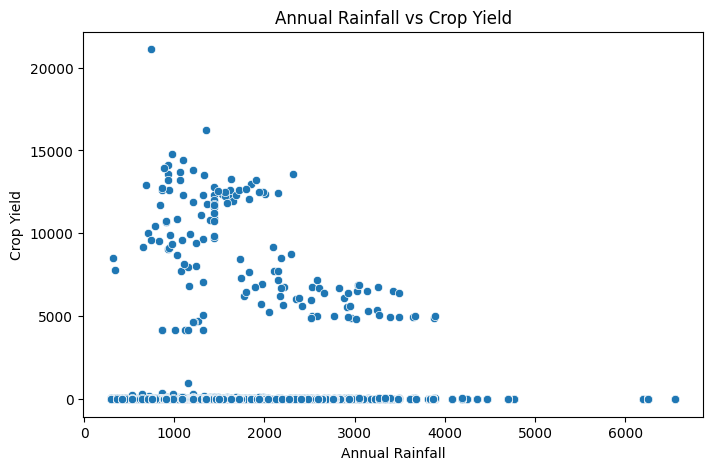

In [46]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=merged_df,
    x="Annual_Rainfall",
    y="Yield"
)

plt.title("Annual Rainfall vs Crop Yield")
plt.xlabel("Annual Rainfall")
plt.ylabel("Crop Yield")

plt.show()

In [47]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (14008, 9)
Testing data: (3502, 9)


In [48]:
categorical_features = [
    "Crop",
    "Season",
    "State"
]

numerical_features = [
    "Crop_Year",
    "Area",
    "Annual_Rainfall",
    "Fertilizer",
    "Pesticide",
    "Season_Temperature"
]

In [49]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

In [50]:
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

In [ ]:
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            DecisionTreeRegressor(
                random_state=42,
                max_depth=20
            )
        )
    ]
)

decision_tree_model.fit(X_train, y_train)

decision_tree_predictions = decision_tree_model.predict(X_test)

In [61]:
gradient_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            GradientBoostingRegressor(
                n_estimators=100,
                learning_rate=0.05,
                max_depth=3,
                random_state=42
            )
        )
    ]
)

print("Starting Gradient Boosting training...")

gradient_model.fit(X_train, y_train)

print("Training completed!")

gradient_predictions = gradient_model.predict(X_test)

print("Prediction completed!")

Starting Gradient Boosting training...
Training completed!
Prediction completed!


In [62]:
gradient_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            GradientBoostingRegressor(
                n_estimators=200,
                learning_rate=0.05,
                random_state=42
            )
        )
    ]
)

gradient_model.fit(X_train, y_train)

gradient_predictions = gradient_model.predict(X_test)

In [63]:
def evaluate_model(name, y_true, predictions):

    mae = mean_absolute_error(y_true, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_true, predictions)
    )

    r2 = r2_score(y_true, predictions)

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    }



In [66]:
print(type(linear_predictions))

<class 'numpy.ndarray'>


In [67]:
print(type(decision_tree_predictions))

<class 'numpy.ndarray'>


In [69]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (14008, 9)
X_test: (3502, 9)
y_train: (14008,)
y_test: (3502,)


In [70]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=50,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

print("Training Random Forest...")

random_forest_model.fit(X_train, y_train)

print("Training completed!")

Training Random Forest...
Training completed!


In [71]:
random_forest_predictions = random_forest_model.predict(X_test)

print("Prediction completed!")

Prediction completed!


In [72]:
print(type(random_forest_predictions))

<class 'numpy.ndarray'>


In [73]:
results = []

results.append(
    evaluate_model(
        "Linear Regression",
        y_test,
        linear_predictions
    )
)

results.append(
    evaluate_model(
        "Decision Tree",
        y_test,
        decision_tree_predictions
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        random_forest_predictions
    )
)

results.append(
    evaluate_model(
        "Gradient Boosting",
        y_test,
        gradient_predictions
    )
)

results_df = pd.DataFrame(results)

results_df

,Model,MAE,RMSE,R2 Score
0,Linear Regression,144.111884,788.908393,-0.000198
1,Decision Tree,10.154160,150.466361,0.963616
2,Random Forest,9.329498,120.252151,0.976761
3,Gradient Boosting,10.288077,111.807471,0.979910


In [74]:
best_model_name = results_df.loc[
    results_df["R2 Score"].idxmax(),
    "Model"
]

print("Best Model:", best_model_name)

Best Model: Gradient Boosting


In [75]:
models = {
    "Linear Regression": linear_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_model
}

best_model = models[best_model_name]

print("Selected model:", best_model_name)

Selected model: Gradient Boosting


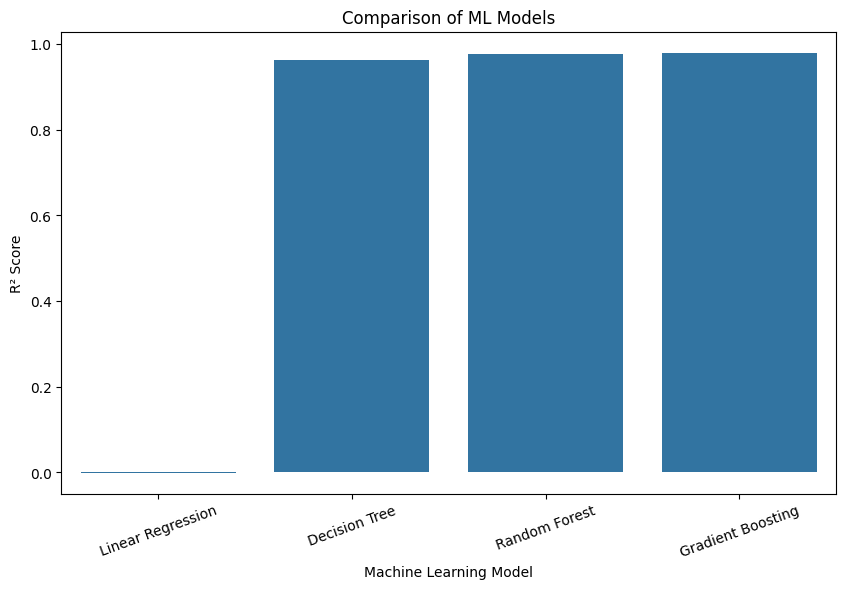

In [76]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2 Score"
)

plt.title("Comparison of ML Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("R² Score")

plt.xticks(rotation=20)

plt.show()

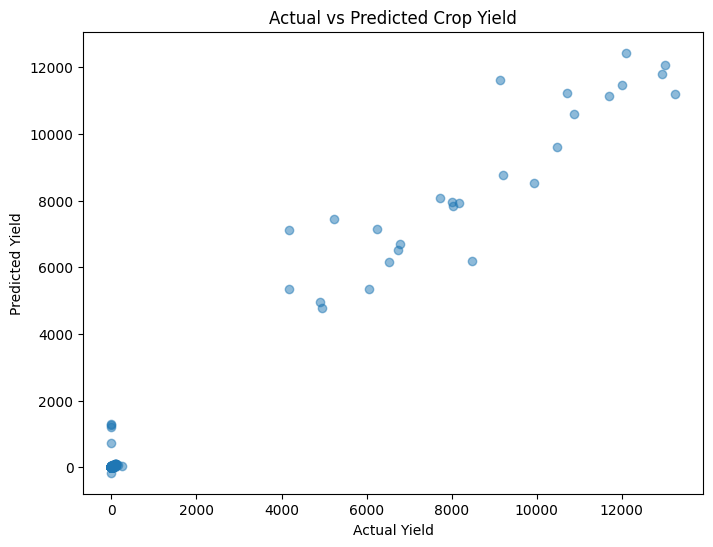

In [77]:
best_predictions = best_model.predict(X_test)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.5
)

plt.xlabel("Actual Yield")
plt.ylabel("Predicted Yield")

plt.title("Actual vs Predicted Crop Yield")

plt.show()

In [78]:
rainfall_low = merged_df["Annual_Rainfall"].quantile(0.25)
rainfall_high = merged_df["Annual_Rainfall"].quantile(0.75)

temperature_low = merged_df["Season_Temperature"].quantile(0.25)
temperature_high = merged_df["Season_Temperature"].quantile(0.75)

print("Rainfall Low:", rainfall_low)
print("Rainfall High:", rainfall_high)

print("Temperature Low:", temperature_low)
print("Temperature High:", temperature_high)

Rainfall Low: 927.5
Rainfall High: 1643.7
Temperature Low: 27.235
Temperature High: 31.75


In [79]:
def calculate_risk(rainfall, temperature):

    risk_score = 0

    # Rainfall risk
    if rainfall < rainfall_low:
        risk_score += 1

    elif rainfall > rainfall_high:
        risk_score += 1

    # Temperature risk
    if temperature < temperature_low:
        risk_score += 1

    elif temperature > temperature_high:
        risk_score += 1

    # Final risk
    if risk_score == 0:
        return "Low Risk"

    elif risk_score == 1:
        return "Medium Risk"

    else:
        return "High Risk"

In [80]:
test_rainfall = merged_df["Annual_Rainfall"].iloc[0]

test_temperature = merged_df["Season_Temperature"].iloc[0]

risk = calculate_risk(
    test_rainfall,
    test_temperature
)

print("Rainfall:", test_rainfall)
print("Temperature:", test_temperature)
print("Agricultural Risk:", risk)

Rainfall: 2051.4
Temperature: 29.05
Agricultural Risk: Medium Risk


In [81]:
def get_recommendation(risk):

    if risk == "Low Risk":
        return "Conditions are relatively favorable. Continue normal crop monitoring."

    elif risk == "Medium Risk":
        return "Monitor rainfall and temperature closely. Consider irrigation or drainage based on field conditions."

    else:
        return "Weather conditions are unusual. Closely monitor the crop and consider irrigation, drainage, or expert agricultural advice."

In [82]:
print(get_recommendation(risk))

Monitor rainfall and temperature closely. Consider irrigation or drainage based on field conditions.


In [83]:
joblib.dump(
    best_model,
    "crop_yield_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [84]:
files.download("crop_yield_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [85]:
files.download("crop_yield_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [86]:
risk_values = {
    "rainfall_low": rainfall_low,
    "rainfall_high": rainfall_high,
    "temperature_low": temperature_low,
    "temperature_high": temperature_high
}

joblib.dump(
    risk_values,
    "risk_thresholds.pkl"
)

print("Risk thresholds saved!")

Risk thresholds saved!


In [87]:
files.download("risk_thresholds.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [88]:
merged_df.to_csv(
    "final_crop_dataset.csv",
    index=False
)

files.download("final_crop_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>